# QKE on MNIST 2 & 9
This notebook is run on Google Colab.
Reference Sites for PennyLane Implementation:
https://pennylane.ai/demos/tutorial_kernel_based_training

https://pennylane.ai/demos/tutorial_kernels_module?utm_source=chatgpt.com

In [1]:
# Install Packages
%pip install -q pennylane scikit-learn matplotlib

In [2]:

import time
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

SEED = 42
N_TRAIN = 150
N_TEST = 50
N_QUBITS = 6
N_REPEATS = 2

# None = exact analytic kernel
# 1024 = finite-shot estimation
SHOTS = None

# Load 28 x 28 MNIST images as flattened 784-pixel vectors.
# The first run downloads MNIST; subsequent runs use the local cache.
data = fetch_openml(name="mnist_784", version=1, as_frame=False)
digits = data.target.astype(np.int64)
digit_mask = np.isin(digits, [2, 9])
X = data.data[digit_mask].astype(np.float64)
# Keep binary labels for the unchanged F1 evaluation: 2 -> 0, 9 -> 1.
y = (digits[digit_mask] == 9).astype(np.int64)
data.target_names = np.array(["2", "9"])

# Select 200 samples, stratified by class
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=N_TRAIN,
    test_size=N_TEST,
    stratify=y,
    random_state=SEED
)

print("Original dataset:", X.shape)
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Class names:", data.target_names)

Original dataset: (13948, 784)
Training set: (150, 784)
Testing set: (50, 784)
Class names: ['2' '9']


In [3]:

# Normalize pixels to [0, 1]; PCA centers them during fitting.

X_train_scaled = X_train / 255.0
X_test_scaled = X_test / 255.0

# Reduce feature dimension to number of qubits
pca = PCA(n_components=N_QUBITS, random_state=SEED)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Rescale PCA features into encoding angles
angle_scaler = MinMaxScaler(
    feature_range=(-np.pi / 2, np.pi / 2)
)

X_train_q = angle_scaler.fit_transform(X_train_pca)
X_test_q = angle_scaler.transform(X_test_pca)

print("Quantum training data:", X_train_q.shape)
print("Quantum testing data:", X_test_q.shape)

print(
    "PCA explained variance:",
    round(sum(pca.explained_variance_ratio_), 4)
)

Quantum training data: (150, 6)
Quantum testing data: (50, 6)
PCA explained variance: 0.4656


In [4]:

# Create the quantum simulator
device = qml.device(
    "lightning.qubit",
    wires=N_QUBITS,
    shots=SHOTS
)

# Define the quantum feature map
def feature_map(x):
    qml.IQPEmbedding(
        features=x,
        wires=range(N_QUBITS),
        n_repeats=N_REPEATS
    )

# Quantum kernel evaluation circuit
@qml.qnode(device)
def kernel_circuit(x1, x2):

    # Encode the first sample
    feature_map(x1)

    # Apply inverse encoding of second sample
    qml.adjoint(feature_map)(x2)

    # Probability of returning to |000...0>
    return qml.probs(wires=range(N_QUBITS))

# Return the kernel similarity
def quantum_kernel(x1, x2):
    return float(kernel_circuit(x1, x2)[0])

# Sanity check
print(
    "K(x1, x1) =",
    quantum_kernel(X_train_q[0], X_train_q[0])
)

print(
    "K(x1, x2) =",
    quantum_kernel(X_train_q[0], X_train_q[1])
)

K(x1, x1) = 0.9999999999999953
K(x1, x2) = 0.1356545082869231


In [5]:

def training_kernel_matrix(X):

    n = len(X)
    K = np.eye(n)

    for i in range(n):
        for j in range(i + 1, n):
            value = quantum_kernel(X[i], X[j])
            K[i, j] = value
            K[j, i] = value

    return K


def testing_kernel_matrix(X_test, X_train):

    K = np.zeros((len(X_test), len(X_train)))

    for i in range(len(X_test)):
        for j in range(len(X_train)):
            K[i, j] = quantum_kernel(
                X_test[i], X_train[j]
            )

    return K


start = time.perf_counter()

print("Computing training kernel matrix...")
K_train = training_kernel_matrix(X_train_q)

print("Computing testing kernel matrix...")
K_test = testing_kernel_matrix(
    X_test_q, X_train_q
)

kernel_time = time.perf_counter() - start

print("Training kernel shape:", K_train.shape)
print("Testing kernel shape:", K_test.shape)
print("Kernel computation time (s):", round(kernel_time, 2))

Computing training kernel matrix...
Computing testing kernel matrix...
Training kernel shape: (150, 150)
Testing kernel shape: (50, 150)
Kernel computation time (s): 202.22


===== Quantum Kernel SVM Results =====
Accuracy: 0.8800
F1 Score: 0.8750
Kernel computation: 202.22 s
SVM fitting/prediction: 0.01 s

Classification report:
              precision    recall  f1-score   support

           2       0.85      0.92      0.88        25
           9       0.91      0.84      0.88        25

    accuracy                           0.88        50
   macro avg       0.88      0.88      0.88        50
weighted avg       0.88      0.88      0.88        50



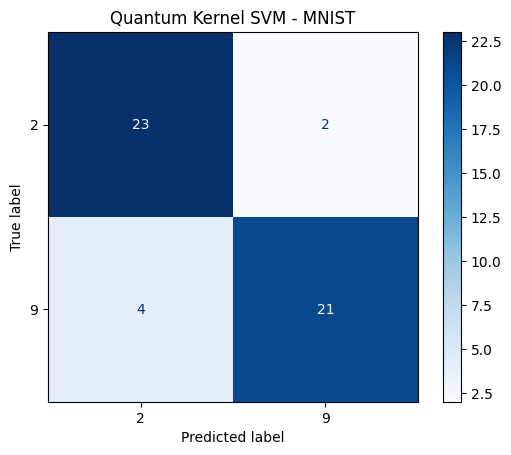

In [6]:

# Train classical SVM with the quantum kernel
svm = SVC(kernel="precomputed", C=1.0)

start = time.perf_counter()

svm.fit(K_train, y_train)
y_pred = svm.predict(K_test)

svm_time = time.perf_counter() - start

# Metrics
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("===== Quantum Kernel SVM Results =====")
print(f"Accuracy: {accuracy:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Kernel computation: {kernel_time:.2f} s")
print(f"SVM fitting/prediction: {svm_time:.2f} s")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=data.target_names,
    cmap="Blues"
)

plt.title("Quantum Kernel SVM - MNIST")
plt.show()


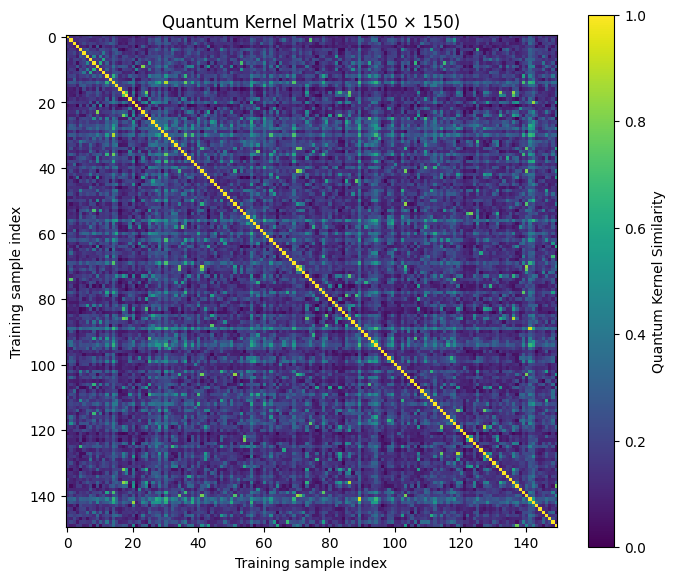

Minimum eigenvalue: 0.022418319484177326
Maximum eigenvalue: 31.2952866035599
Mean off-diagonal similarity: 0.19115972011484234


In [7]:

plt.figure(figsize=(7, 6))

plt.imshow(K_train, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="Quantum Kernel Similarity")

plt.xlabel("Training sample index")
plt.ylabel("Training sample index")
plt.title("Quantum Kernel Matrix (150 × 150)")

plt.tight_layout()
plt.show()

# Numerical kernel diagnostics
eigenvalues = np.linalg.eigvalsh(K_train)

print("Minimum eigenvalue:", eigenvalues.min())
print("Maximum eigenvalue:", eigenvalues.max())
print("Mean off-diagonal similarity:",
      K_train[np.triu_indices(N_TRAIN, k=1)].mean())


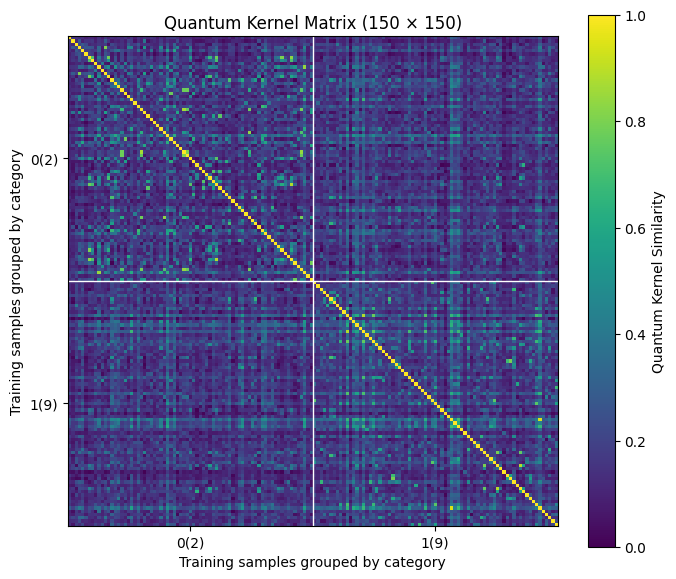

Minimum eigenvalue: 0.022418319484177326
Maximum eigenvalue: 31.2952866035599
Mean off-diagonal similarity: 0.19115972011484234


In [8]:

# Group both axes by class: benign (1), then malignant (0).
train_order = np.argsort(-y_train, kind="stable")
K_train_sorted = K_train[np.ix_(train_order, train_order)]
n_benign = np.count_nonzero(y_train == 1)
class_centers = [(n_benign - 1) / 2, (n_benign + len(y_train) - 1) / 2]

plt.figure(figsize=(7, 6))

plt.imshow(K_train_sorted, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="Quantum Kernel Similarity")

plt.xticks(class_centers, ["0(2)", "1(9)"])
plt.yticks(class_centers, ["0(2)", "1(9)"])
plt.axvline(n_benign - 0.5, color="white", linewidth=1)
plt.axhline(n_benign - 0.5, color="white", linewidth=1)
plt.xlabel("Training samples grouped by category")
plt.ylabel("Training samples grouped by category")
plt.title("Quantum Kernel Matrix (150 × 150)")

plt.tight_layout()
plt.show()

# Numerical kernel diagnostics
eigenvalues = np.linalg.eigvalsh(K_train)

print("Minimum eigenvalue:", eigenvalues.min())
print("Maximum eigenvalue:", eigenvalues.max())
print("Mean off-diagonal similarity:",
      K_train[np.triu_indices(N_TRAIN, k=1)].mean())
